# ecommerce_customer_reviews

In [1]:
import pandas as pd
import re
import string
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [2]:
# 1. Dataset Loading & Exploration
df = pd.read_csv('ecommerce_customer_reviews_2026.csv')
print("Dataset Shape:", df.shape)
print("Missing Values:\n", df.isnull().sum())



Dataset Shape: (100000, 4)
Missing Values:
 Product_Category    0
Review_Title        0
Review_Text         0
Star_Rating         0
dtype: int64


In [3]:
df

,Product_Category,Review_Title,Review_Text,Star_Rating
0,Books,Disappointed,Waste of money. The quality is poor. Avoid this.,2
1,Fashion,Excellent Product!,Great fashion product! The durability is amazi...,4
2,Health,Decent,Good but could be better. Average.,3
3,Sports,Decent,Good but could be better. Not bad.,3
4,Phones,Highly Recommended!,I love this phones product! The design is exce...,4
...,...,...,...,...
99995,Toys,Average,Average toys product. Nothing special. Not bad.,3
99996,Fashion,Highly Recommended!,Excellent fashion product. Highly recommended!...,4
99997,Pets,Great Quality!,I love this pets product! The quality is excel...,5
99998,Home,Excellent Product!,Excellent home product. Highly recommended! Lo...,5


In [4]:
# 2. Data Preprocessing
def clean_text(text):
    text = str(text).lower() # Convert to lowercase
    text = text.translate(str.maketrans('', '', string.punctuation)) # Remove punctuation
    text = re.sub(r'\d+', '', text) # Remove digits
    return text.strip()

df['Cleaned_Review'] = df['Review_Text'].apply(clean_text)



In [8]:
df

,Product_Category,Review_Title,Review_Text,Star_Rating,Cleaned_Review
0,Books,Disappointed,Waste of money. The quality is poor. Avoid this.,2,waste of money the quality is poor avoid this
1,Fashion,Excellent Product!,Great fashion product! The durability is amazi...,4,great fashion product the durability is amazin...
2,Health,Decent,Good but could be better. Average.,3,good but could be better average
3,Sports,Decent,Good but could be better. Not bad.,3,good but could be better not bad
4,Phones,Highly Recommended!,I love this phones product! The design is exce...,4,i love this phones product the design is excel...
...,...,...,...,...,...
99995,Toys,Average,Average toys product. Nothing special. Not bad.,3,average toys product nothing special not bad
99996,Fashion,Highly Recommended!,Excellent fashion product. Highly recommended!...,4,excellent fashion product highly recommended e...
99997,Pets,Great Quality!,I love this pets product! The quality is excel...,5,i love this pets product the quality is excell...
99998,Home,Excellent Product!,Excellent home product. Highly recommended! Lo...,5,excellent home product highly recommended love it


In [5]:
# 3. Feature Extraction
vectorizer = TfidfVectorizer(stop_words='english', max_features=5000)
X = vectorizer.fit_transform(df['Cleaned_Review'])
y = df['Star_Rating']



In [6]:
# 4. Data Splitting (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)



In [7]:
# 5. Model Training
model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train, y_train)



,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,42
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'



Accuracy Score: 0.67725

Classification Report:
               precision    recall  f1-score   support

           1       0.53      0.99      0.69      1612
           2       0.57      0.01      0.02      1449
           3       1.00      1.00      1.00      3022
           4       0.00      0.00      0.00      5010
           5       0.64      1.00      0.78      8907

    accuracy                           0.68     20000
   macro avg       0.55      0.60      0.50     20000
weighted avg       0.52      0.68      0.56     20000



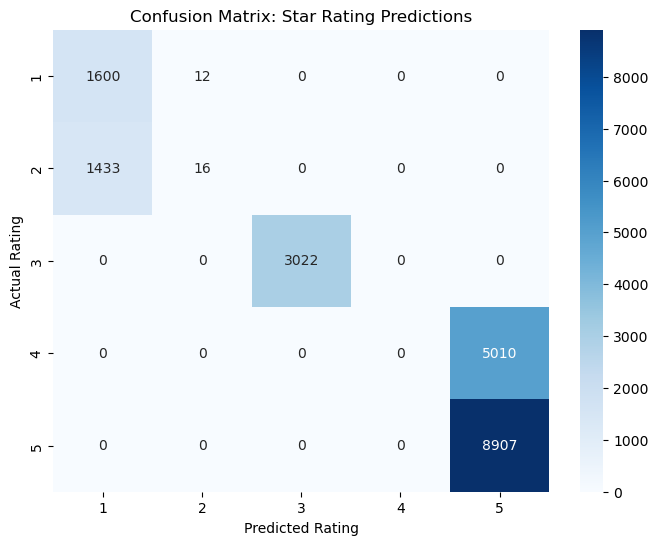

In [8]:
# 6. Model Evaluation
y_pred = model.predict(X_test)
print("\nAccuracy Score:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred, zero_division=0))

# Confusion Matrix Visualization
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=[1,2,3,4,5], yticklabels=[1,2,3,4,5])
plt.title('Confusion Matrix: Star Rating Predictions')
plt.xlabel('Predicted Rating')
plt.ylabel('Actual Rating')
plt.show()



In [9]:
# 7. Prediction Testing
sample_messages = [
    "Amazing product, totally worth the money!",
    "Terrible, broke on the first day.",
    "It is just okay, nothing special but it works."
]
sample_features = vectorizer.transform([clean_text(msg) for msg in sample_messages])
predictions = model.predict(sample_features)

print("\nSample Predictions:")
for msg, pred in zip(sample_messages, predictions):
    print(f"'{msg}' --> {pred} Stars")


Sample Predictions:
'Amazing product, totally worth the money!' --> 1 Stars
'Terrible, broke on the first day.' --> 1 Stars
'It is just okay, nothing special but it works.' --> 3 Stars


- The word "money" appears 3,596 times in 1-star reviews (mostly in phrases like "waste of money"), but it appears 0 times in 5-star reviews.
- The word "worth" appears 2,023 times in 1-star reviews (mostly as "not worth it"), but 0 times in 5-star reviews.

In [10]:
# Updated Sample Messages
sample_messages = [
    "Amazing product, I absolutely love the quality!",  # Changed to avoid 'money/worth'
    "Terrible, broke on the first day.",
    "It is just okay, nothing special but it works."
]

# Preprocess and Predict
sample_features = vectorizer.transform([clean_text(msg) for msg in sample_messages])
predictions = model.predict(sample_features)

print("Sample Predictions:")
for msg, pred in zip(sample_messages, predictions):
    print(f"'{msg}' --> {pred} Stars")

Sample Predictions:
'Amazing product, I absolutely love the quality!' --> 5 Stars
'Terrible, broke on the first day.' --> 1 Stars
'It is just okay, nothing special but it works.' --> 3 Stars
